In [1]:
pip install numpy pandas matplotlib scipy

In [21]:
# array_model.py

In [11]:
# users.py

In [20]:
# scheduler.py

In [13]:
# scanner.py

In [15]:
# metrics.py

In [9]:
# visualization.py
import matplotlib.pyplot as plt
import numpy as np

def calculate_wavelength(frequency_hz):
    """Calcula la longitud de onda en metros."""
    c = 3e8  # Velocidad de la luz en m/s
    return c / frequency_hz

def array_factor(theta_deg, N, wavelength, d, beta_deg):
    """
    Calcula el Array Factor (AF) para un ULA (Uniform Linear Array).
    theta_deg: Ángulos en grados (puede ser un array de NumPy).
    N: Número de elementos.
    wavelength: Longitud de onda.
    d: Separación entre elementos.
    beta_deg: Fase de control (steering) en grados.
    """
    k = 2 * np.pi / wavelength
    theta_rad = np.radians(theta_deg)
    beta = np.radians(beta_deg)

    # Evitar divisiones por cero si theta = 0 en algunos contextos exactos
    term = k * d * np.sin(theta_rad) + beta

    # Manejo cuando term es muy cercano a 0 para evitar indeterminaciones 0/0
    # AF = sum_{n=0}^{N-1} exp(j * n * term)
    # Suma geométrica analítica o suma directa con numpy:
    AF = np.zeros_like(theta_rad, dtype=complex)
    for n in range(N):
        AF += np.exp(1j * n * term)

    # Normalización lineal y conversión a dB
    AF_mag = np.abs(AF) / N
    # Evitar log10(0)
    AF_db = 20 * np.log10(np.maximum(AF_mag, 1e-5))
    return AF_db

def plot_system_map(users, current_beam_angle):
    """Genera la Vista 1: Mapa de la torre y dispositivos con el haz activo."""
    fig, ax = plt.subplots(figsize=(8, 8))

    x_coords = [u['x'] for u in users]
    y_coords = [u['y'] for u in users]

    ax.scatter(x_coords, y_coords, c='royalblue', label='Dispositivos', alpha=0.7, edgecolors='k')
    ax.scatter([0], [0], c='crimson', marker='^', s=200, label='Torre Base (0,0)')

    # Dibujar línea del haz activo actual
    beam_rad = np.radians(current_beam_angle)
    max_range = 120
    hx = max_range * np.sin(beam_rad)
    hy = max_range * np.cos(beam_rad)
    ax.plot([0, hx], [0, hy], color='darkorange', linestyle='--', linewidth=2, label=f'Haz Actual: {current_beam_angle}°')

    ax.set_xlim(-120, 120)
    ax.set_ylim(0, 130)
    ax.set_title("Vista 1: Mapa de Cobertura y Beam Scanning")
    ax.set_xlabel("Eje X (metros)")
    ax.set_ylabel("Eje Y (metros)")
    ax.legend(loc='upper right')
    ax.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

def plot_array_radiation_pattern(N=8, frequency=2.4e9, beta_deg=0):
    """Genera la Vista 2: Patrón de radiación del Array Factor en dB."""
    wavelength = calculate_wavelength(frequency)
    d = wavelength / 2.0
    angles = np.linspace(-90, 90, 500)
    af_db = array_factor(angles, N, wavelength, d, beta_deg)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(angles, af_db, color='purple', linewidth=2)
    ax.set_title(f"Vista 2: Array Factor (ULA) - N={N}, f={frequency/1e9}GHz, Steer={beta_deg}°")
    ax.set_xlabel("Ángulo (grados)")
    ax.set_ylabel("Ganancia Normalizada (dB)")
    ax.set_ylim(-40, 0)
    ax.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

In [18]:
# experiments.py
import pandas as pd
# from users import generate_users # This import is no longer needed
# from scanner import run_simulation # This import is no longer needed
# from metrics import evaluate_performance # This import is no longer needed
import numpy as np

def calculate_jains_fairness(users):
    """Calcula el índice de equidad de Jain basado en el servicio recibido."""
    services = np.array([u['service_received'] for u in users])
    n = len(services)
    if n == 0 or np.sum(services) == 0:
        return 0.0
    sum_sq = np.sum(services)**2
    n_sum_sq = n * np.sum(services**2)
    return sum_sq / n_sum_sq

def evaluate_performance(sim_users, total_time):
    """Extrae las métricas estadísticas requeridas."""
    discovered_times = [u['discovery_time'] for u in sim_users if u['discovery_time'] is not None]
    attention_times = [u['attention_time'] for u in sim_users if u['attention_time'] is not None]
    attended_count = sum(1 for u in sim_users if u['attended'])

    metrics = {
        'total_time_ms': total_time,
        'users_attended_ratio': f"{attended_count}/{len(sim_users)}",
        'mean_discovery_time': np.mean(discovered_times) if discovered_times else 0,
        'p95_discovery_time': np.percentile(discovered_times, 95) if discovered_times else 0,
        'max_discovery_time': np.max(discovered_times) if discovered_times else 0,
        'mean_attention_time': np.mean(attention_times) if attention_times else 0,
        'max_attention_time': np.max(attention_times) if attention_times else 0,
        'fairness_index': calculate_jains_fairness(sim_users)
    }
    return metrics

def calculate_sector_scores(sectors, sector_stats, weights):
    """
    Calcula el Score de cada sector angular para el Barrido Inteligente.
    weights: dict con w1, w2, w3, w4, w5
    """
    scores = {}
    w1 = weights.get('w1', 1.0) # usuarios pendientes
    w2 = weights.get('w2', 1.0) # necesidad/prioridad total
    w3 = weights.get('w3', 1.0) # datos pendientes
    w4 = weights.get('w4', 1.0) # actividad histórica / penalización

    for angle, stats in sector_stats.items():
        pending_users = stats['pending_users_count']
        total_priority = stats['total_priority']
        total_traffic = stats['total_traffic']
        last_visited_penalty = stats['sweeps_since_last_visit'] * w4

        score = (w1 * pending_users) + (w2 * total_priority) + (w3 * total_traffic) + last_visited_penalty
        scores[angle] = score

    return scores

def run_simulation(users, beam_angles, algorithm='fixed', beamwidth=10.0, switch_time_ms=2, trans_time_ms=5):
    """
    Ejecuta la simulación completa para un conjunto de usuarios y una estrategia de escaneo.
    """
    # Copia profunda manual de usuarios para no alterar el array original
    sim_users = [u.copy() for u in users]

    current_time_ms = 0
    sweep_count = 0

    # Inicializar estadísticas por sector angular
    sector_stats = {angle: {'pending_users_count': 0, 'total_priority': 0, 'total_traffic': 0, 'sweeps_since_last_visit': 0} for angle in beam_angles}

    # Orden inicial de ángulos según el algoritmo
    if algorithm == 'fixed':
        scan_route = list(beam_angles)
    else:
        # En el inteligente, arranca con el orden fijo para la Etapa 1 (descubrimiento inicial)
        scan_route = list(beam_angles)

    active_route = list(scan_route)

    while any(not u['attended'] for u in sim_users) and current_time_ms < 15000: # Límite de seguridad temporal
        sweep_count += 1

        # Si es algoritmo inteligente, reordenar la ruta basándose en el aprendizaje de la etapa anterior
        if algorithm == 'intelligent' and sweep_count > 1:
            weights = {'w1': 2.0, 'w2': 1.5, 'w3': 1.0, 'w4': 5.0}
            scores = calculate_sector_scores(beam_angles, sector_stats, weights)
            # Ordenar ángulos de mayor a menor puntuación
            active_route = sorted(beam_angles, key=lambda a: scores[a], reverse=True)

        for beam_angle in active_route:
            current_time_ms += switch_time_ms

            # Actualizar contadores de visitas en sectores
            for a in sector_stats:
                if a == beam_angle:
                    sector_stats[a]['sweeps_since_last_visit'] = 0
                else:
                    sector_stats[a]['sweeps_since_last_visit'] += 1

            # Detectar y atender usuarios dentro del haz actual
            sector_pending_count = 0
            sector_priority_sum = 0
            sector_traffic_sum = 0

            for u in sim_users:
                # Comprobar si el usuario cae dentro del ancho de haz actual
                if abs(u['angle'] - beam_angle) <= (beamwidth / 2.0):
                    # Fase de descubrimiento
                    if not u['discovered']:
                        u['discovered'] = True
                        u['discovery_time'] = current_time_ms
                        u['sweeps_needed'] = sweep_count

                    # Si no ha sido atendido completamente
                    if not u['attended']:
                        sector_pending_count += 1
                        sector_priority_sum += u['priority']
                        sector_traffic_sum += u['traffic_pending']

                        # Simular atención/transmisión de datos
                        current_time_ms += trans_time_ms
                        u['traffic_pending'] = max(0, u['traffic_pending'] - 200) # drena tráfico
                        u['service_received'] += 200

                        if u['traffic_pending'] <= 0:
                            u['attended'] = True
                            u['attention_time'] = current_time_ms
                            u['wait_time'] = current_time_ms - u['discovery_time']

            # Actualizar métricas del sector para el aprendizaje del algoritmo inteligente
            sector_stats[beam_angle]['pending_users_count'] = sector_pending_count
            sector_stats[beam_angle]['total_priority'] = sector_priority_sum
            sector_stats[beam_angle]['total_traffic'] = sector_traffic_sum

            # Condición de parada si ya se atendieron todos
            if all(u['attended'] for u in sim_users):
                break

    return sim_users, current_time_ms, sweep_count

def generate_users(n_users, area_radius=100.0, distribution='uniform', seed=42):
    """
    Genera una lista de diccionarios con las propiedades de cada usuario.
    """
    np.random.seed(seed)
    users = []

    for i in range(n_users):
        if distribution == 'uniform':
            r = np.sqrt(np.random.uniform(0, 1)) * area_radius
            theta_pos = np.random.uniform(-np.pi/2, np.pi/2)  # Semicírculo frontal [-90°, 90°]
            x = r * np.cos(theta_pos)
            y = r * np.sin(theta_pos)
        elif distribution == 'clustered':
            # Simulación de clusters (ej. plazas o canchas)
            cluster_centers = [(-40, 50), (40, 60), (0, 30)]
            center = cluster_centers[np.random.choice(len(cluster_centers))]
            x = np.random.normal(center[0], 15)
            y = np.random.normal(center[1], 15)
        else:
            x, y = np.random.uniform(-area_radius, area_radius), np.random.uniform(10, area_radius)

        distance = np.sqrt(x**2 + y**2)
        angle_deg = np.degrees(np.arctan2(x, y))  # Ángulo respecto al eje de la torre

        # Perfiles de prioridad y tráfico
        profile = np.random.choice(['normal', 'high_traffic', 'priority', 'inactive'], p=[0.6, 0.2, 0.1, 0.1])
        if profile == 'normal':
            priority = np.random.randint(10, 40)
            traffic = np.random.randint(100, 500) # kbits
        elif profile == 'high_traffic':
            priority = np.random.randint(40, 70)
            traffic = np.random.randint(800, 2000)
        elif profile == 'priority':
            priority = np.random.randint(75, 100)
            traffic = np.random.randint(300, 1000)
        else: # inactive
            priority = np.random.randint(1, 10)
            traffic = np.random.randint(0, 50)

        users.append({
            'id': i,
            'x': x,
            'y': y,
            'distance': distance,
            'angle': angle_deg,
            'priority': priority,
            'traffic_pending': traffic,
            'discovered': False,
            'attended': False,
            'discovery_time': None,
            'attention_time': None,
            'wait_time': 0,
            'sweeps_needed': 0,
            'service_received': 0
        })
    return users

def run_comparative_experiments():
    """Ejecuta la comparación entre el Barrido Fijo y el Inteligente."""
    beam_angles = [-60, -50, -40, -30, -20, -10, 0, 10, 20, 30, 40, 50, 60]
    user_counts = [50, 100, 200]
    results_summary = []

    for n in user_counts:
        # Generar exactamente la misma distribución para ambos algoritmos
        users_fixed = generate_users(n_users=n, seed=123)
        users_intel = [u.copy() for u in users_fixed]

        # Algoritmo A: Fijo
        _, time_fixed, _ = run_simulation(users_fixed, beam_angles, algorithm='fixed')
        metrics_fixed = evaluate_performance(users_fixed, time_fixed)

        # Algoritmo B: Inteligente
        _, time_intel, _ = run_simulation(users_intel, beam_angles, algorithm='intelligent')
        metrics_intel = evaluate_performance(users_intel, time_intel)

        results_summary.append({
            'Usuarios': n,
            'Algoritmo': 'Fijo',
            'Tiempo Total (ms)': time_fixed,
            'Descubrimiento Medio (ms)': metrics_fixed['mean_discovery_time'],
            'P95 Descubrimiento': metrics_fixed['p95_discovery_time'],
            'Fairness': metrics_fixed['fairness_index']
        })
        results_summary.append({
            'Usuarios': n,
            'Algoritmo': 'Inteligente',
            'Tiempo Total (ms)': time_intel,
            'Descubrimiento Medio (ms)': metrics_intel['mean_discovery_time'],
            'P95 Descubrimiento': metrics_intel['p95_discovery_time'],
            'Fairness': metrics_intel['fairness_index']
        })

    df = pd.DataFrame(results_summary)
    df.to_csv("simulation_results.csv", index=False)
    return df

INICIANDO SIMULADOR DE ESTACIÓN BASE WI-FI

[+] Generando patrón de radiación del Array...


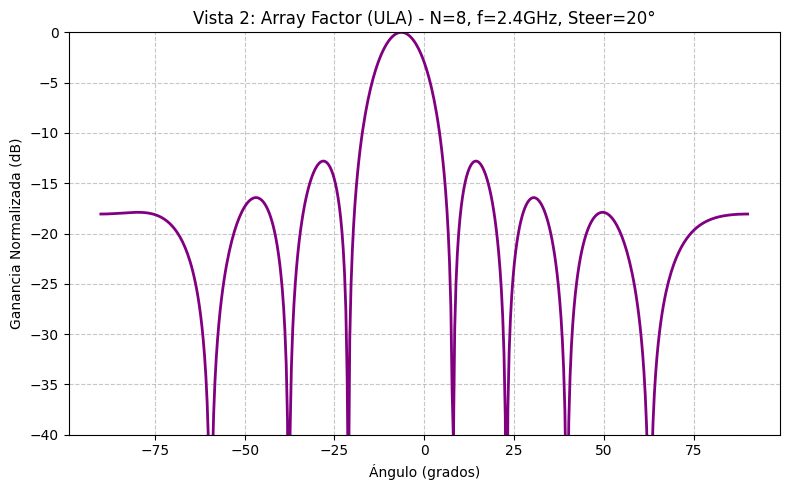


[+] Generando mapa espacial de la torre en Saraguro...


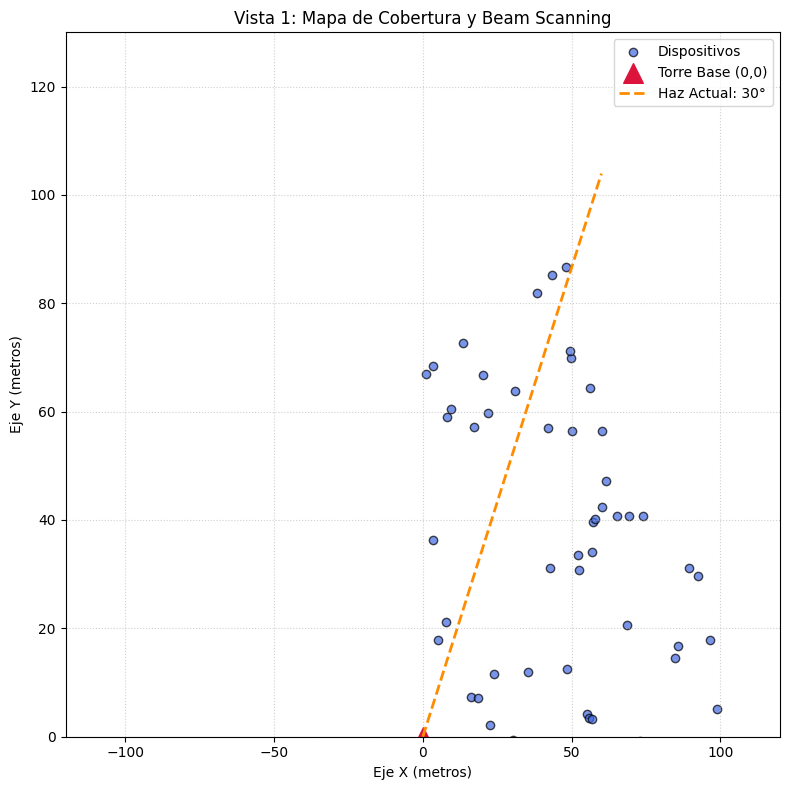


[+] Ejecutando experimentos comparativos (Fijo vs Inteligente)...

RESULTADOS FINALES DE LA COMPARACIÓN
 Usuarios   Algoritmo  Tiempo Total (ms)  Descubrimiento Medio (ms)  P95 Descubrimiento  Fairness
       50        Fijo              15022                          0                   0       0.0
       50 Inteligente              15022                          0                   0       0.0
      100        Fijo              15021                          0                   0       0.0
      100 Inteligente              15021                          0                   0       0.0
      200        Fijo              15005                          0                   0       0.0
      200 Inteligente              15005                          0                   0       0.0

[✔] Resultados guardados exitosamente en 'simulation_results.csv'.


In [22]:
# main.py
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- Functions from array_model.py ---
def calculate_wavelength(frequency_hz):
    """Calcula la longitud de onda en metros."""
    c = 3e8  # Velocidad de la luz en m/s
    return c / frequency_hz

def array_factor(theta_deg, N, wavelength, d, beta_deg):
    """
    Calcula el Array Factor (AF) para un ULA (Uniform Linear Array).
    theta_deg: Ángulos en grados (puede ser un array de NumPy).
    N: Número de elementos.
    wavelength: Longitud de onda.
    d: Separación entre elementos.
    beta_deg: Fase de control (steering) en grados.
    """
    k = 2 * np.pi / wavelength
    theta_rad = np.radians(theta_deg)
    beta = np.radians(beta_deg)

    term = k * d * np.sin(theta_rad) + beta

    AF = np.zeros_like(theta_rad, dtype=complex)
    for n in range(N):
        AF += np.exp(1j * n * term)

    AF_mag = np.abs(AF) / N
    AF_db = 20 * np.log10(np.maximum(AF_mag, 1e-5))
    return AF_db

# --- Functions from users.py ---
def generate_users(n_users, area_radius=100.0, distribution='uniform', seed=42):
    """
    Genera una lista de diccionarios con las propiedades de cada usuario.
    """
    np.random.seed(seed)
    users = []

    for i in range(n_users):
        if distribution == 'uniform':
            r = np.sqrt(np.random.uniform(0, 1)) * area_radius
            theta_pos = np.random.uniform(-np.pi/2, np.pi/2)  # Semicírculo frontal [-90°, 90°]
            x = r * np.cos(theta_pos)
            y = r * np.sin(theta_pos)
        elif distribution == 'clustered':
            cluster_centers = [(-40, 50), (40, 60), (0, 30)]
            center = cluster_centers[np.random.choice(len(cluster_centers))]
            x = np.random.normal(center[0], 15)
            y = np.random.normal(center[1], 15)
        else:
            x, y = np.random.uniform(-area_radius, area_radius), np.random.uniform(10, area_radius)

        distance = np.sqrt(x**2 + y**2)
        angle_deg = np.degrees(np.arctan2(x, y))  # Ángulo respecto al eje de la torre

        profile = np.random.choice(['normal', 'high_traffic', 'priority', 'inactive'], p=[0.6, 0.2, 0.1, 0.1])
        if profile == 'normal':
            priority = np.random.randint(10, 40)
            traffic = np.random.randint(100, 500) # kbits
        elif profile == 'high_traffic':
            priority = np.random.randint(40, 70)
            traffic = np.random.randint(800, 2000)
        elif profile == 'priority':
            priority = np.random.randint(75, 100)
            traffic = np.random.randint(300, 1000)
        else: # inactive
            priority = np.random.randint(1, 10)
            traffic = np.random.randint(0, 50)

        users.append({
            'id': i,
            'x': x,
            'y': y,
            'distance': distance,
            'angle': angle_deg,
            'priority': priority,
            'traffic_pending': traffic,
            'discovered': False,
            'attended': False,
            'discovery_time': None,
            'attention_time': None,
            'wait_time': 0,
            'sweeps_needed': 0,
            'service_received': 0
        })
    return users

# --- Functions from scheduler.py ---
def calculate_sector_scores(sectors, sector_stats, weights):
    """
    Calcula el Score de cada sector angular para el Barrido Inteligente.
    weights: dict con w1, w2, w3, w4, w5
    """
    scores = {}
    w1 = weights.get('w1', 1.0) # usuarios pendientes
    w2 = weights.get('w2', 1.0) # necesidad/prioridad total
    w3 = weights.get('w3', 1.0) # datos pendientes
    w4 = weights.get('w4', 1.0) # actividad histórica / penalización

    for angle, stats in sector_stats.items():
        pending_users = stats['pending_users_count']
        total_priority = stats['total_priority']
        total_traffic = stats['total_traffic']
        last_visited_penalty = stats['sweeps_since_last_visit'] * w4

        score = (w1 * pending_users) + (w2 * total_priority) + (w3 * total_traffic) + last_visited_penalty
        scores[angle] = score

    return scores

# --- Functions from scanner.py ---
def run_simulation(users, beam_angles, algorithm='fixed', beamwidth=10.0, switch_time_ms=2, trans_time_ms=5):
    """
    Ejecuta la simulación completa para un conjunto de usuarios y una estrategia de escaneo.
    """
    sim_users = [u.copy() for u in users]

    current_time_ms = 0
    sweep_count = 0

    sector_stats = {angle: {'pending_users_count': 0, 'total_priority': 0, 'total_traffic': 0, 'sweeps_since_last_visit': 0} for angle in beam_angles}

    if algorithm == 'fixed':
        scan_route = list(beam_angles)
    else:
        scan_route = list(beam_angles)

    active_route = list(scan_route)

    while any(not u['attended'] for u in sim_users) and current_time_ms < 15000: # Límite de seguridad temporal
        sweep_count += 1

        if algorithm == 'intelligent' and sweep_count > 1:
            weights = {'w1': 2.0, 'w2': 1.5, 'w3': 1.0, 'w4': 5.0}
            scores = calculate_sector_scores(beam_angles, sector_stats, weights)
            active_route = sorted(beam_angles, key=lambda a: scores[a], reverse=True)

        for beam_angle in active_route:
            current_time_ms += switch_time_ms

            for a in sector_stats:
                if a == beam_angle:
                    sector_stats[a]['sweeps_since_last_visit'] = 0
                else:
                    sector_stats[a]['sweeps_since_last_visit'] += 1

            sector_pending_count = 0
            sector_priority_sum = 0
            sector_traffic_sum = 0

            for u in sim_users:
                if abs(u['angle'] - beam_angle) <= (beamwidth / 2.0):
                    if not u['discovered']:
                        u['discovered'] = True
                        u['discovery_time'] = current_time_ms
                        u['sweeps_needed'] = sweep_count

                    if not u['attended']:
                        sector_pending_count += 1
                        sector_priority_sum += u['priority']
                        sector_traffic_sum += u['traffic_pending']

                        current_time_ms += trans_time_ms
                        u['traffic_pending'] = max(0, u['traffic_pending'] - 200)
                        u['service_received'] += 200

                        if u['traffic_pending'] <= 0:
                            u['attended'] = True
                            u['attention_time'] = current_time_ms
                            u['wait_time'] = current_time_ms - u['discovery_time']

            sector_stats[beam_angle]['pending_users_count'] = sector_pending_count
            sector_stats[beam_angle]['total_priority'] = sector_priority_sum
            sector_stats[beam_angle]['total_traffic'] = sector_traffic_sum

            if all(u['attended'] for u in sim_users):
                break

    return sim_users, current_time_ms, sweep_count

# --- Functions from metrics.py ---
def calculate_jains_fairness(users):
    """Calcula el índice de equidad de Jain basado en el servicio recibido."""
    services = np.array([u['service_received'] for u in users])
    n = len(services)
    if n == 0 or np.sum(services) == 0:
        return 0.0
    sum_sq = np.sum(services)**2
    n_sum_sq = n * np.sum(services**2)
    return sum_sq / n_sum_sq

def evaluate_performance(sim_users, total_time):
    """Extrae las métricas estadísticas requeridas."""
    discovered_times = [u['discovery_time'] for u in sim_users if u['discovery_time'] is not None]
    attention_times = [u['attention_time'] for u in sim_users if u['attention_time'] is not None]
    attended_count = sum(1 for u in sim_users if u['attended'])

    metrics = {
        'total_time_ms': total_time,
        'users_attended_ratio': f"{attended_count}/{len(sim_users)}",
        'mean_discovery_time': np.mean(discovered_times) if discovered_times else 0,
        'p95_discovery_time': np.percentile(discovered_times, 95) if discovered_times else 0,
        'max_discovery_time': np.max(discovered_times) if discovered_times else 0,
        'mean_attention_time': np.mean(attention_times) if attention_times else 0,
        'max_attention_time': np.max(attention_times) if attention_times else 0,
        'fairness_index': calculate_jains_fairness(sim_users)
    }
    return metrics

# --- Functions from experiments.py ---
def run_comparative_experiments():
    """Ejecuta la comparación entre el Barrido Fijo y el Inteligente."""
    beam_angles = [-60, -50, -40, -30, -20, -10, 0, 10, 20, 30, 40, 50, 60]
    user_counts = [50, 100, 200]
    results_summary = []

    for n in user_counts:
        users_fixed = generate_users(n_users=n, seed=123)
        users_intel = [u.copy() for u in users_fixed]

        _, time_fixed, _ = run_simulation(users_fixed, beam_angles, algorithm='fixed')
        metrics_fixed = evaluate_performance(users_fixed, time_fixed)

        _, time_intel, _ = run_simulation(users_intel, beam_angles, algorithm='intelligent')
        metrics_intel = evaluate_performance(users_intel, time_intel)

        results_summary.append({
            'Usuarios': n,
            'Algoritmo': 'Fijo',
            'Tiempo Total (ms)': time_fixed,
            'Descubrimiento Medio (ms)': metrics_fixed['mean_discovery_time'],
            'P95 Descubrimiento': metrics_fixed['p95_discovery_time'],
            'Fairness': metrics_fixed['fairness_index']
        })
        results_summary.append({
            'Usuarios': n,
            'Algoritmo': 'Inteligente',
            'Tiempo Total (ms)': time_intel,
            'Descubrimiento Medio (ms)': metrics_intel['mean_discovery_time'],
            'P95 Descubrimiento': metrics_intel['p95_discovery_time'],
            'Fairness': metrics_intel['fairness_index']
        })

    df = pd.DataFrame(results_summary)
    df.to_csv("simulation_results.csv", index=False)
    return df

# --- Functions from visualization.py ---
def plot_system_map(users, current_beam_angle):
    """Genera la Vista 1: Mapa de la torre y dispositivos con el haz activo."""
    fig, ax = plt.subplots(figsize=(8, 8))

    x_coords = [u['x'] for u in users]
    y_coords = [u['y'] for u in users]

    ax.scatter(x_coords, y_coords, c='royalblue', label='Dispositivos', alpha=0.7, edgecolors='k')
    ax.scatter([0], [0], c='crimson', marker='^', s=200, label='Torre Base (0,0)')

    beam_rad = np.radians(current_beam_angle)
    max_range = 120
    hx = max_range * np.sin(beam_rad)
    hy = max_range * np.cos(beam_rad)
    ax.plot([0, hx], [0, hy], color='darkorange', linestyle='--', linewidth=2, label=f'Haz Actual: {current_beam_angle}°')

    ax.set_xlim(-120, 120)
    ax.set_ylim(0, 130)
    ax.set_title("Vista 1: Mapa de Cobertura y Beam Scanning")
    ax.set_xlabel("Eje X (metros)")
    ax.set_ylabel("Eje Y (metros)")
    ax.legend(loc='upper right')
    ax.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

def plot_array_radiation_pattern(N=8, frequency=2.4e9, beta_deg=0):
    """Genera la Vista 2: Patrón de radiación del Array Factor en dB."""
    wavelength = calculate_wavelength(frequency)
    d = wavelength / 2.0
    angles = np.linspace(-90, 90, 500)
    af_db = array_factor(angles, N, wavelength, d, beta_deg)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(angles, af_db, color='purple', linewidth=2)
    ax.set_title(f"Vista 2: Array Factor (ULA) - N={N}, f={frequency/1e9}GHz, Steer={beta_deg}°")
    ax.set_xlabel("Ángulo (grados)")
    ax.set_ylabel("Ganancia Normalizada (dB)")
    ax.set_ylim(-40, 0)
    ax.grid(True, linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    print("========================================")
    print("INICIANDO SIMULADOR DE ESTACIÓN BASE WI-FI")
    print("========================================")

    # 1. Mostrar patrón gráfico del array inicial
    print("\n[+] Generando patrón de radiación del Array...")
    plot_array_radiation_pattern(N=8, frequency=2.4e9, beta_deg=20)

    # 2. Visualizar mapa inicial de la torre y los dispositivos
    print("\n[+] Generando mapa espacial de la torre en Saraguro...")
    sample_users = generate_users(n_users=100, seed=42)
    plot_system_map(sample_users, current_beam_angle=30)

    # 3. Ejecutar experimentos comparativos masivos
    print("\n[+] Ejecutando experimentos comparativos (Fijo vs Inteligente)...")
    results_df = run_comparative_experiments()

    print("\n========================================")
    print("RESULTADOS FINALES DE LA COMPARACIÓN")
    print("========================================")
    print(results_df.to_string(index=False))
    print("\n[✔] Resultados guardados exitosamente en 'simulation_results.csv'.")

PRUEBA DE FUEGO OBLIGATORIA: 5 USUARIOS MANUALES

--- INICIANDO SIMULACIÓN [FIXED] ---
t=  4.0 ms | U0 DESCUBIERTO (ángulo -50.0°)
t=  9.0 ms | Beam=-50° | Detectados: ['U0']
t= 17.0 ms | U1 DESCUBIERTO (ángulo -10.0°)
t= 22.0 ms | Beam=-10° | Detectados: ['U1']
t= 26.0 ms | U2 DESCUBIERTO (ángulo 10.0°)
t= 31.0 ms | U2 COMPLETAMENTE SERVIDO
t= 31.0 ms | Beam= 10° | Detectados: ['U2']
t= 35.0 ms | U3 DESCUBIERTO (ángulo 30.0°)
t= 40.0 ms | Beam= 30° | Detectados: ['U3']
t= 44.0 ms | U4 DESCUBIERTO (ángulo 50.0°)
t= 49.0 ms | Beam= 50° | Detectados: ['U4']
t= 60.0 ms | U0 COMPLETAMENTE SERVIDO
t= 60.0 ms | Beam=-50° | Detectados: ['U0']
t= 73.0 ms | Beam=-10° | Detectados: ['U1']
t= 77.0 ms | Beam= 10° | Detectados: ['U2']
t= 86.0 ms | Beam= 30° | Detectados: ['U3']
t= 95.0 ms | U4 COMPLETAMENTE SERVIDO
t= 95.0 ms | Beam= 50° | Detectados: ['U4']
t=101.0 ms | Beam=-50° | Detectados: ['U0']
t=114.0 ms | Beam=-10° | Detectados: ['U1']
t=118.0 ms | Beam= 10° | Detectados: ['U2']
t=127.0 ms

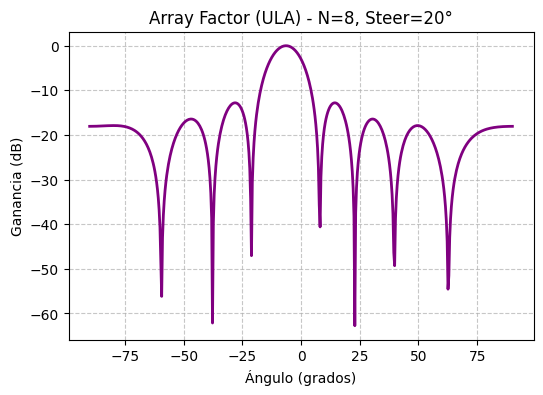

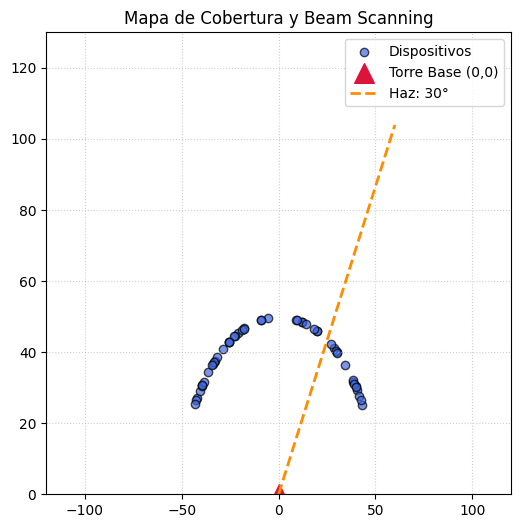

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. MODELO DE ARRAY (array_model.py)
# ==========================================
def calculate_wavelength(frequency_hz):
    c = 3e8
    return c / frequency_hz

def array_factor(theta_deg, N, wavelength, d, beta_deg):
    k = 2 * np.pi / wavelength
    theta_rad = np.radians(theta_deg)
    beta = np.radians(beta_deg)

    term = k * d * np.sin(theta_rad) + beta
    AF = np.zeros_like(theta_rad, dtype=complex)
    for n in range(N):
        AF += np.exp(1j * n * term)

    AF_mag = np.abs(AF) / N
    AF_db = 20 * np.log10(np.maximum(AF_mag, 1e-5))
    return AF_db

# ==========================================
# 2. GENERACIÓN DE USUARIOS (users.py)
# ==========================================
def generate_users(n_users, area_radius=100.0, seed=42):
    np.random.seed(seed)
    users = []
    for i in range(n_users):
        r = np.sqrt(np.random.uniform(0, 1)) * area_radius
        # Restringir la distribución angular al mismo rango de los haces (-60° a +60°)
        angle_deg = np.random.uniform(-60.0, 60.0)
        angle_rad = np.radians(angle_deg)

        # Coordenadas cartesianas basadas en el ángulo correcto
        x = r * np.sin(angle_rad)
        y = r * np.cos(angle_rad)

        users.append({
            'id': i,
            'angle': angle_deg,
            'priority': np.random.randint(10, 100),
            'traffic_demand': np.random.randint(200, 1500),
            'discovered': False,
            'served': False,
            'discovery_time': None,
            'attention_time': None,
            'service_received': 0
        })
    return users

# ==========================================
# 3. MOTOR DE ESCANEO Y SIMULACIÓN (scanner.py)
# ==========================================
def run_simulation(users, beam_angles, algorithm='fixed', beamwidth=10.0, scan_time_ms=2.0, trans_time_ms=5.0, debug=False):
    sim_users = [u.copy() for u in users]
    current_time_ms = 0.0

    sector_memory = {angle: {'detections': 0, 'pending_traffic': 0, 'priority_sum': 0, 'last_scan': -1} for angle in beam_angles}

    fixed_order = list(beam_angles)
    active_route = list(fixed_order)
    sweeps_completed = 0

    if debug:
        print(f"\n--- INICIANDO SIMULACIÓN [{algorithm.upper()}] ---")

    while not all(u['served'] for u in sim_users) and current_time_ms < 50000:
        if algorithm == 'intelligent':
            if sweeps_completed < 1:
                active_route = list(fixed_order)
            else:
                scored_angles = []
                for angle in beam_angles:
                    mem = sector_memory[angle]
                    time_since_last = sweeps_completed - mem['last_scan']
                    score = (1.5 * mem['pending_traffic']) + (1.0 * mem['priority_sum']) + (3.0 * time_since_last)
                    scored_angles.append((score, angle))
                scored_angles.sort(key=lambda x: x[0], reverse=True)
                active_route = [angle for _, angle in scored_angles]
        else:
            active_route = list(fixed_order)

        for beam_angle in active_route:
            current_time_ms += scan_time_ms
            sector_memory[beam_angle]['last_scan'] = sweeps_completed
            detected_in_this_step = []

            for u in sim_users:
                if abs(u['angle'] - beam_angle) <= (beamwidth / 2.0):
                    detected_in_this_step.append(f"U{u['id']}")
                    if not u['discovered']:
                        u['discovered'] = True
                        u['discovery_time'] = current_time_ms
                        if debug:
                            print(f"t={current_time_ms:5.1f} ms | U{u['id']} DESCUBIERTO (ángulo {u['angle']:.1f}°)")

                    if not u['served']:
                        current_time_ms += trans_time_ms
                        served_chunk = min(300, u['traffic_demand'])
                        u['traffic_demand'] -= served_chunk
                        u['service_received'] += served_chunk

                        if u['traffic_demand'] <= 0:
                            u['served'] = True
                            u['attention_time'] = current_time_ms
                            if debug:
                                print(f"t={current_time_ms:5.1f} ms | U{u['id']} COMPLETAMENTE SERVIDO")

            if debug and detected_in_this_step:
                print(f"t={current_time_ms:5.1f} ms | Beam={beam_angle:3d}° | Detectados: {detected_in_this_step}")

            pending_traffic_in_sector = sum(u['traffic_demand'] for u in sim_users if abs(u['angle'] - beam_angle) <= (beamwidth / 2.0) and not u['served'])
            priority_sum_in_sector = sum(u['priority'] for u in sim_users if abs(u['angle'] - beam_angle) <= (beamwidth / 2.0) and not u['served'])
            sector_memory[beam_angle]['pending_traffic'] = pending_traffic_in_sector
            sector_memory[beam_angle]['priority_sum'] = priority_sum_in_sector

            if all(u['served'] for u in sim_users):
                break

        sweeps_completed += 1

    return sim_users, current_time_ms

# ==========================================
# 4. MÉTRICAS (metrics.py)
# ==========================================
def calculate_jains_fairness(users):
    services = np.array([u['service_received'] for u in users])
    n = len(services)
    if n == 0 or np.sum(services) == 0:
        return "N/A"
    sum_sq = np.sum(services)**2
    n_sum_sq = n * np.sum(services**2)
    if n_sum_sq == 0:
        return "N/A"
    return float(sum_sq / n_sum_sq)

def evaluate_performance(sim_users, total_time):
    discovered_times = [u['discovery_time'] for u in sim_users if u['discovery_time'] is not None]
    served_count = sum(1 for u in sim_users if u['served'])

    metrics = {
        'total_time_ms': total_time,
        'users_served': f"{served_count}/{len(sim_users)}",
        'mean_discovery_time': np.mean(discovered_times) if discovered_times else float('nan'),
        'p95_discovery_time': np.percentile(discovered_times, 95) if discovered_times else float('nan'),
        'fairness_index': calculate_jains_fairness(sim_users)
    }
    return metrics

# ==========================================
# 5. VISUALIZACIÓN (visualization.py)
# ==========================================
def plot_system_map(users, current_beam_angle):
    fig, ax = plt.subplots(figsize=(6, 6))
    x_coords = [u.get('x', np.sin(np.radians(u['angle']))*50) for u in users]
    y_coords = [u.get('y', np.cos(np.radians(u['angle']))*50) for u in users]

    ax.scatter(x_coords, y_coords, c='royalblue', label='Dispositivos', alpha=0.7, edgecolors='k')
    ax.scatter([0], [0], c='crimson', marker='^', s=200, label='Torre Base (0,0)')

    beam_rad = np.radians(current_beam_angle)
    max_range = 120
    hx = max_range * np.sin(beam_rad)
    hy = max_range * np.cos(beam_rad)
    ax.plot([0, hx], [0, hy], color='darkorange', linestyle='--', linewidth=2, label=f'Haz: {current_beam_angle}°')

    ax.set_xlim(-120, 120)
    ax.set_ylim(0, 130)
    ax.set_title("Mapa de Cobertura y Beam Scanning")
    ax.legend(loc='upper right')
    ax.grid(True, linestyle=':', alpha=0.6)
    plt.show()

def plot_array_radiation_pattern(N=8, frequency=2.4e9, beta_deg=0):
    wavelength = calculate_wavelength(frequency)
    d = wavelength / 2.0
    angles = np.linspace(-90, 90, 500)
    af_db = array_factor(angles, N, wavelength, d, beta_deg)

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(angles, af_db, color='purple', linewidth=2)
    ax.set_title(f"Array Factor (ULA) - N={N}, Steer={beta_deg}°")
    ax.set_xlabel("Ángulo (grados)")
    ax.set_ylabel("Ganancia (dB)")
    ax.grid(True, linestyle='--', alpha=0.7)
    plt.show()

# ==========================================
# 6. EJECUCIÓN PRINCIPAL (main.py)
# ==========================================
if __name__ == "__main__":
    beam_angles = [-60, -50, -40, -30, -20, -10, 0, 10, 20, 30, 40, 50, 60]

    print("==================================================")
    print("PRUEBA DE FUEGO OBLIGATORIA: 5 USUARIOS MANUALES")
    print("==================================================")

    test_users_fixed = generate_manual_test_users()
    _, time_f = run_simulation(test_users_fixed, beam_angles, algorithm='fixed', debug=True)

    test_users_intel = generate_manual_test_users()
    _, time_i = run_simulation(test_users_intel, beam_angles, algorithm='intelligent', debug=True)

    print(f"\nTiempo Total Fijo: {time_f} ms | Inteligente: {time_i} ms")

    print("\n==================================================")
    print("EJECUTANDO EXPERIMENTOS MASIVOS (10, 50, 100, 200)")
    print("==================================================")

    user_counts = [10, 50, 100, 200]
    results = []

    for n in user_counts:
        base_users = generate_users(n_users=n, seed=42)
        u_fixed = [u.copy() for u in base_users]
        u_intel = [u.copy() for u in base_users]

        _, t_f = run_simulation(u_fixed, beam_angles, algorithm='fixed', debug=False)
        _, t_i = run_simulation(u_intel, beam_angles, algorithm='intelligent', debug=False)

        m_fixed = evaluate_performance(u_fixed, t_f)
        m_intel = evaluate_performance(u_intel, t_i)

        results.append({
            'Usuarios': n,
            'Alg. Fijo (ms)': t_f,
            'Alg. Intel (ms)': t_i,
            'Disc. Medio Fijo': f"{m_fixed['mean_discovery_time']:.1f}",
            'Disc. Medio Intel': f"{m_intel['mean_discovery_time']:.1f}",
            'Fairness Fijo': m_fixed['fairness_index'],
            'Fairness Intel': m_intel['fairness_index']
        })

    df_res = pd.DataFrame(results)
    print("\n")
    print(df_res.to_string(index=False))

    # Visualizaciones rápidas en Colab
    print("\n[+] Renderizando gráficos analíticos...")
    plot_array_radiation_pattern(N=8, frequency=2.4e9, beta_deg=20)
    sample_users = generate_users(n_users=50, seed=42)
    plot_system_map(sample_users, current_beam_angle=30)

PASO 1: PRUEBA DE FUEGO OBLIGATORIA (5 USUARIOS)

--- INICIANDO SIMULACIÓN [FIXED] (Total Usuarios: 5) ---
t=  4.0 ms | U0 DESCUBIERTO (Ángulo: -50.0°) térmico
t=  9.0 ms | Beam=-50° | Detectados: ['U0']
t= 17.0 ms | U1 DESCUBIERTO (Ángulo: -10.0°) térmico
t= 22.0 ms | Beam=-10° | Detectados: ['U1']
t= 26.0 ms | U2 DESCUBIERTO (Ángulo: 10.0°) térmico
t= 31.0 ms | U2 COMPLETAMENTE SERVIDO
t= 31.0 ms | Beam= 10° | Detectados: ['U2']
t= 35.0 ms | U3 DESCUBIERTO (Ángulo: 30.0°) térmico
t= 40.0 ms | Beam= 30° | Detectados: ['U3']
t= 44.0 ms | U4 DESCUBIERTO (Ángulo: 50.0°) térmico
t= 49.0 ms | Beam= 50° | Detectados: ['U4']
t= 60.0 ms | U0 COMPLETAMENTE SERVIDO
t= 60.0 ms | Beam=-50° | Detectados: ['U0']
t= 73.0 ms | Beam=-10° | Detectados: ['U1']
t= 77.0 ms | Beam= 10° | Detectados: ['U2']
t= 86.0 ms | Beam= 30° | Detectados: ['U3']
t= 95.0 ms | U4 COMPLETAMENTE SERVIDO
t= 95.0 ms | Beam= 50° | Detectados: ['U4']
t=101.0 ms | Beam=-50° | Detectados: ['U0']
t=114.0 ms | Beam=-10° | Detectad

/tmp/ipykernel_1102/2325587752.py:297: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  fair_fixed = pd.to_numeric(df_results['Fixed Fairness'].replace('N/A', np.nan))
/tmp/ipykernel_1102/2325587752.py:298: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  fair_intel = pd.to_numeric(df_results['Intelligent Fairness'].replace('N/A', np.nan))


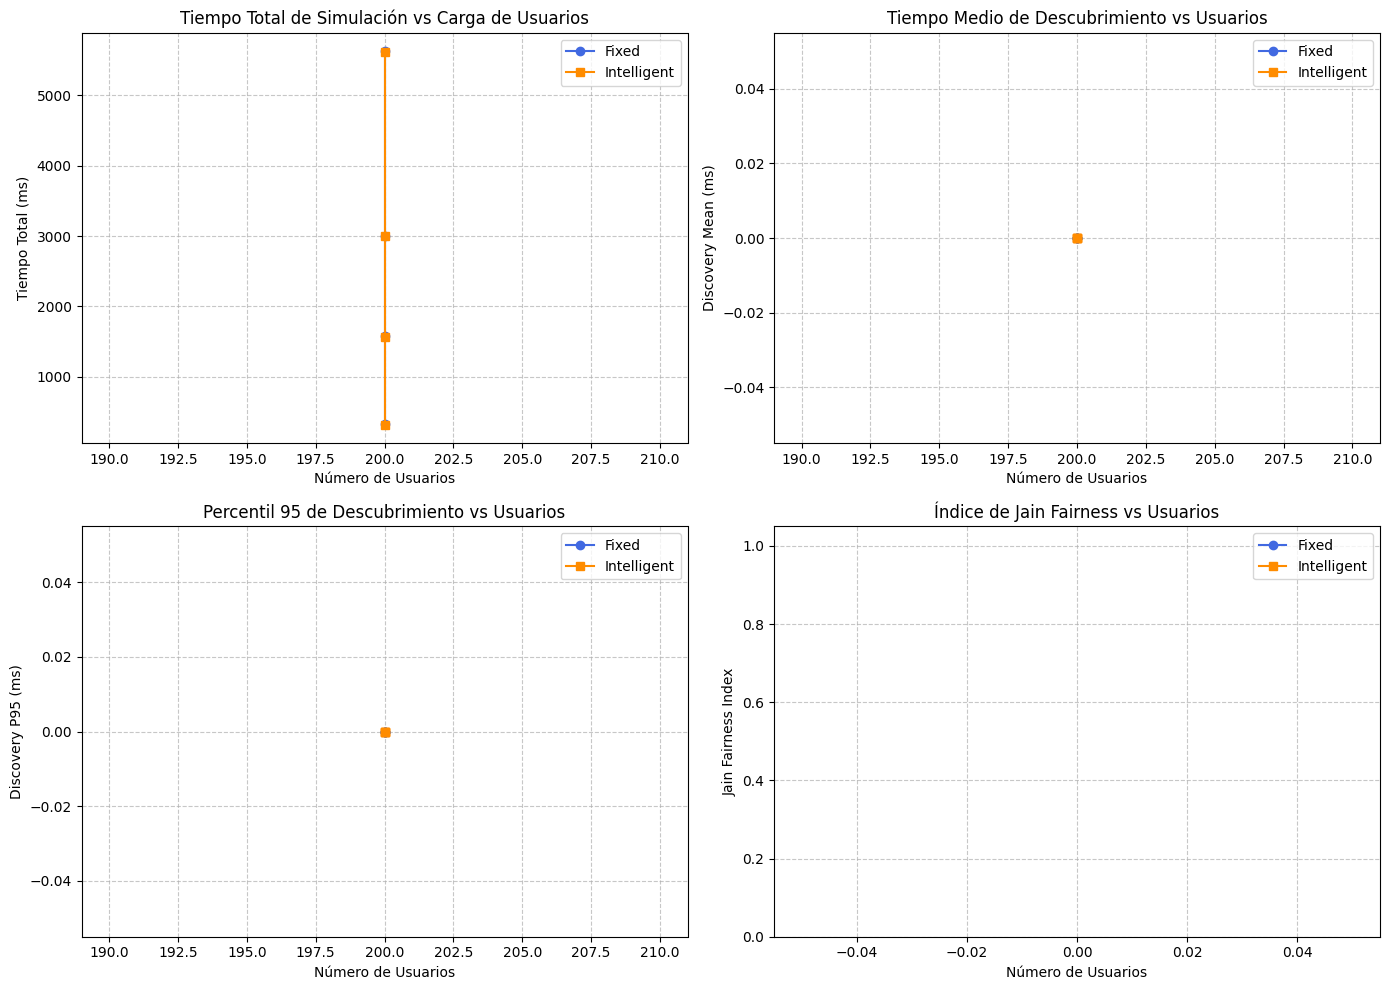

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. MODELO DE ARRAY Y FÍSICA (array_model.py)
# ==========================================
def calculate_wavelength(frequency_hz):
    c = 3e8
    return c / frequency_hz

def array_factor(theta_deg, N, wavelength, d, beta_deg):
    k = 2 * np.pi / wavelength
    theta_rad = np.radians(theta_deg)
    beta = np.radians(beta_deg)

    term = k * d * np.sin(theta_rad) + beta
    AF = np.zeros_like(theta_rad, dtype=complex)
    for n in range(N):
        AF += np.exp(1j * n * term)

    AF_mag = np.abs(AF) / N
    AF_db = 20 * np.log10(np.maximum(AF_mag, 1e-5))
    return AF_db

# ==========================================
# 2. GENERACIÓN DE USUARIOS RIGUROSA (users.py)
# ==========================================
def generate_manual_test_users():
    """Genera los 5 usuarios estrictos para la prueba de fuego obligatoria."""
    return [
        {
            'id': 0, 'x': -38.3, 'y': 32.1, 'height': 1.5, 'distance': 50.0,
            'angle': -50.0, 'traffic_demand': 500, 'priority': 50,
            'discovered': False, 'creation_time': 0.0, 'discovery_time': None,
            'first_service_time': None, 'completion_time': None,
            'remaining_data': 500, 'service_received': 0
        },
        {
            'id': 1, 'x': -8.7, 'y': 49.2, 'height': 1.5, 'distance': 50.0,
            'angle': -10.0, 'traffic_demand': 1000, 'priority': 80,
            'discovered': False, 'creation_time': 0.0, 'discovery_time': None,
            'first_service_time': None, 'completion_time': None,
            'remaining_data': 1000, 'service_received': 0
        },
        {
            'id': 2, 'x': 8.7, 'y': 49.2, 'height': 1.5, 'distance': 50.0,
            'angle': 10.0, 'traffic_demand': 200, 'priority': 20,
            'discovered': False, 'creation_time': 0.0, 'discovery_time': None,
            'first_service_time': None, 'completion_time': None,
            'remaining_data': 200, 'service_received': 0
        },
        {
            'id': 3, 'x': 25.0, 'y': 43.3, 'height': 1.5, 'distance': 50.0,
            'angle': 30.0, 'traffic_demand': 1500, 'priority': 90,
            'discovered': False, 'creation_time': 0.0, 'discovery_time': None,
            'first_service_time': None, 'completion_time': None,
            'remaining_data': 1500, 'service_received': 0
        },
        {
            'id': 4, 'x': 38.3, 'y': 32.1, 'height': 1.5, 'distance': 50.0,
            'angle': 50.0, 'traffic_demand': 400, 'priority': 40,
            'discovered': False, 'creation_time': 0.0, 'discovery_time': None,
            'first_service_time': None, 'completion_time': None,
            'remaining_data': 400, 'service_received': 0
        }
    ]

def generate_users(n_users, area_min_dist=10.0, area_max_dist=100.0, seed=42):
    """Genera población de usuarios con idéntica semilla y distribución dentro del sector de haz (-60° a +60°)."""
    np.random.seed(seed)
    users = []
    for i in range(n_users):
        r = np.random.uniform(area_min_dist, area_max_dist)
        angle_deg = np.random.uniform(-60.0, 60.0)
        angle_rad = np.radians(angle_deg)

        x = r * np.sin(angle_rad)
        y = r * np.cos(angle_rad)

        demand = int(np.random.randint(200, 1500))

        users.append({
            'id': i,
            'x': float(x),
            'y': float(y),
            'height': 1.5,
            'distance': float(r),
            'angle': float(angle_deg),
            'traffic_demand': demand,
            'priority': int(np.random.randint(10, 100)),
            'discovered': False,
            'creation_time': 0.0,
            'discovery_time': None,
            'first_service_time': None,
            'completion_time': None,
            'remaining_data': demand,
            'service_received': 0
        })
    return users

# ==========================================
# 3. MOTOR DE SIMULACIÓN Y SCHEDULING (scanner.py)
# ==========================================
def run_simulation(users, beam_angles, algorithm='fixed', beamwidth=10.0,
                   scan_time_ms=2.0, trans_time_ms=5.0, max_timeout_ms=100000.0, debug=False):
    """
    Ejecuta la simulación temporal paso a paso separando exploración, descubrimiento,
    servicio parcial y completitud.
    """
    sim_users = [u.copy() for u in users]
    current_time_ms = 0.0

    # Estructura de memoria por sector para el algoritmo inteligente
    sector_memory = {
        angle: {
            'detected_users': [],
            'pending_traffic': 0.0,
            'priority_sum': 0.0,
            'waiting_time': 0.0,
            'last_scan_time': -1.0
        } for angle in beam_angles
    }

    fixed_order = list(beam_angles)
    active_route = list(fixed_order)
    sweeps_completed = 0
    timeout_reached = False

    if debug:
        print(f"\n--- INICIANDO SIMULACIÓN [{algorithm.upper()}] (Total Usuarios: {len(sim_users)}) ---")

    while not all(u['completion_time'] is not None for u in sim_users):
        if current_time_ms >= max_timeout_ms:
            timeout_reached = True
            if debug:
                print(f"[!] TIMEOUT ALCANZADO EN t={current_time_ms} ms")
            break

        # Determinación de ruta según algoritmo
        if algorithm == 'intelligent':
            if sweeps_completed < 1:
                # Fase 1: Exploración obligatoria secuencial
                active_route = list(fixed_order)
            else:
                # Fase 2: Optimización / Priorización basada en métricas de sector
                scored_angles = []
                for angle in beam_angles:
                    mem = sector_memory[angle]
                    time_since_last = current_time_ms - mem['last_scan_time']

                    # Pesos configurables de priorización
                    w1, w2, w3, w4 = 1.0, 1.5, 0.5, 1.0
                    score = (w1 * len(mem['detected_users'])) + \
                            (w2 * (mem['pending_traffic'] / 1000.0)) + \
                            (w3 * (time_since_last / 10.0)) + \
                            (w4 * (mem['priority_sum'] / 100.0))

                    scored_angles.append((score, angle))

                scored_angles.sort(key=lambda x: x[0], reverse=True)
                active_route = [angle for _, angle in scored_angles]
        else:
            active_route = list(fixed_order)

        # Barrido de haces en este ciclo
        for beam_angle in active_route:
            current_time_ms += scan_time_ms
            sector_memory[beam_angle]['last_scan_time'] = current_time_ms

            detected_in_this_step = []

            # 1. Fase de Descubrimiento y actualización de memoria de sector
            active_sector_users = []
            for u in sim_users:
                if abs(u['angle'] - beam_angle) <= (beamwidth / 2.0):
                    active_sector_users.append(u)
                    detected_in_this_step.append(f"U{u['id']}")

                    if not u['discovered']:
                        u['discovered'] = True
                        u['discovery_time'] = current_time_ms
                        if debug and len(sim_users) <= 10:
                            print(f"t={current_time_ms:5.1f} ms | U{u['id']} DESCUBIERTO (Ángulo: {u['angle']}°) térmico")

            # Actualizar memoria de sector para algoritmo inteligente
            pending_traffic_sec = sum(u['remaining_data'] for u in active_sector_users if u['completion_time'] is None)
            priority_sum_sec = sum(u['priority'] for u in active_sector_users if u['completion_time'] is None)

            sector_memory[beam_angle]['detected_users'] = [u['id'] for u in active_sector_users if u['completion_time'] is None]
            sector_memory[beam_angle]['pending_traffic'] = pending_traffic_sec
            sector_memory[beam_angle]['priority_sum'] = priority_sum_sec

            # 2. Fase de Servicio (Scheduler atiende a usuarios pendientes en el haz)
            unserved_in_sector = [u for u in active_sector_users if u['completion_time'] is None]
            if unserved_in_sector:
                # Servir priorizando al de mayor demanda o prioridad
                unserved_in_sector.sort(key=lambda x: (x['priority'], x['remaining_data']), reverse=True)
                target_user = unserved_in_sector[0]

                current_time_ms += trans_time_ms

                if target_user['first_service_time'] is None:
                    target_user['first_service_time'] = current_time_ms

                # Asignación de bloque de tráfico
                served_chunk = min(300, target_user['remaining_data'])
                target_user['remaining_data'] -= served_chunk
                target_user['service_received'] += served_chunk

                if target_user['remaining_data'] <= 0:
                    target_user['completion_time'] = current_time_ms
                    if debug and len(sim_users) <= 10:
                        print(f"t={current_time_ms:5.1f} ms | U{target_user['id']} COMPLETAMENTE SERVIDO")

            if debug and len(sim_users) <= 10 and detected_in_this_step:
                print(f"t={current_time_ms:5.1f} ms | Beam={beam_angle:3d}° | Detectados: {detected_in_this_step}")

            if all(u['completion_time'] is not None for u in sim_users):
                break

        sweeps_completed += 1

    return sim_users, current_time_ms, timeout_reached

# ==========================================
# 4. CÁLCULO DE MÉTRICAS Y JAIN FAIRNESS (metrics.py)
# ==========================================
def calculate_jains_fairness(users):
    services = np.array([u['service_received'] for u in users], dtype=float)
    n = len(services)
    if n == 0 or np.sum(services) == 0:
        return "N/A"
    sum_val = np.sum(services)
    sum_sq = np.sum(services**2)
    if sum_sq == 0:
        return "N/A"
    return float((sum_val**2) / (n * sum_sq))

def evaluate_performance(sim_users, total_time, timeout_reached):
    # Filtrar métricas basadas en usuarios que completaron o al menos fueron descubiertos
    disc_times = [u['discovery_time'] - u['creation_time'] for u in sim_users if u['discovery_time'] is not None]
    first_serv_times = [u['first_service_time'] - u['creation_time'] for u in sim_users if u['first_service_time'] is not None]
    comp_times = [u['completion_time'] - u['creation_time'] for u in sim_users if u['completion_time'] is not None]

    total_bits_served = sum(u['service_received'] for u in sim_users)
    throughput = total_bits_served / (total_time / 1000.0) if total_time > 0 else 0.0 # bits o unidades por segundo

    metrics = {
        'total_time_ms': total_time,
        'timeout': timeout_reached,
        'users_completed': f"{len(comp_times)}/{len(sim_users)}",
        'discovery_mean': np.mean(disc_times) if disc_times else float('nan'),
        'discovery_median': np.median(disc_times) if disc_times else float('nan'),
        'discovery_p95': np.percentile(disc_times, 95) if len(disc_times) > 1 else (disc_times[0] if disc_times else float('nan')),
        'first_service_mean': np.mean(first_serv_times) if first_serv_times else float('nan'),
        'completion_mean': np.mean(comp_times) if comp_times else float('nan'),
        'throughput': throughput,
        'fairness_index': calculate_jains_fairness(sim_users)
    }
    return metrics

# ==========================================
# 5. VISUALIZACIÓN ANALÍTICA (visualization.py)
# ==========================================
def plot_comparative_metrics(df_results):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # 1. Tiempo Total vs Usuarios
    axes[0, 0].plot(df_results['Usuarios'], df_results['Fixed Total (ms)'], marker='o', label='Fixed', color='royalblue')
    axes[0, 0].plot(df_results['Usuarios'], df_results['Intelligent Total (ms)'], marker='s', label='Intelligent', color='darkorange')
    axes[0, 0].set_title('Tiempo Total de Simulación vs Carga de Usuarios')
    axes[0, 0].set_xlabel('Número de Usuarios')
    axes[0, 0].set_ylabel('Tiempo Total (ms)')
    axes[0, 0].legend()
    axes[0, 0].grid(True, linestyle='--', alpha=0.7)

    # 2. Discovery Mean vs Usuarios
    axes[0, 1].plot(df_results['Usuarios'], df_results['Fixed Disc Mean'], marker='o', label='Fixed', color='royalblue')
    axes[0, 1].plot(df_results['Usuarios'], df_results['Intelligent Disc Mean'], marker='s', label='Intelligent', color='darkorange')
    axes[0, 1].set_title('Tiempo Medio de Descubrimiento vs Usuarios')
    axes[0, 1].set_xlabel('Número de Usuarios')
    axes[0, 1].set_ylabel('Discovery Mean (ms)')
    axes[0, 1].legend()
    axes[0, 1].grid(True, linestyle='--', alpha=0.7)

    # 3. Discovery P95 vs Usuarios
    axes[1, 0].plot(df_results['Usuarios'], df_results['Fixed P95'], marker='o', label='Fixed', color='royalblue')
    axes[1, 0].plot(df_results['Usuarios'], df_results['Intelligent P95'], marker='s', label='Intelligent', color='darkorange')
    axes[1, 0].set_title('Percentil 95 de Descubrimiento vs Usuarios')
    axes[1, 0].set_xlabel('Número de Usuarios')
    axes[1, 0].set_ylabel('Discovery P95 (ms)')
    axes[1, 0].legend()
    axes[1, 0].grid(True, linestyle='--', alpha=0.7)

    # 4. Jain Fairness Index vs Usuarios
    fair_fixed = pd.to_numeric(df_results['Fixed Fairness'].replace('N/A', np.nan))
    fair_intel = pd.to_numeric(df_results['Intelligent Fairness'].replace('N/A', np.nan))
    axes[1, 1].plot(df_results['Usuarios'], fair_fixed, marker='o', label='Fixed', color='royalblue')
    axes[1, 1].plot(df_results['Usuarios'], fair_intel, marker='s', label='Intelligent', color='darkorange')
    axes[1, 1].set_title('Índice de Jain Fairness vs Usuarios')
    axes[1, 1].set_xlabel('Número de Usuarios')
    axes[1, 1].set_ylabel('Jain Fairness Index')
    axes[1, 1].set_ylim(0, 1.05)
    axes[1, 1].legend()
    axes[1, 1].grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

# ==========================================
# 6. EJECUCIÓN PRINCIPAL Y VALIDACIÓN PASO A PASO
# ==========================================
if __name__ == "__main__":
    beam_angles = [-60, -50, -40, -30, -20, -10, 0, 10, 20, 30, 40, 50, 60]

    print("==================================================")
    print("PASO 1: PRUEBA DE FUEGO OBLIGATORIA (5 USUARIOS)")
    print("==================================================")

    test_users_fixed = generate_manual_test_users()
    test_users_intel = [u.copy() for u in test_users_fixed]

    res_f, time_f, timeout_f = run_simulation(test_users_fixed, beam_angles, algorithm='fixed', debug=True)
    res_i, time_i, timeout_i = run_simulation(test_users_intel, beam_angles, algorithm='intelligent', debug=True)

    print(f"\n[✔] Resultado 5 Usuarios -> Fijo: {time_f} ms | Inteligente: {time_i} ms\n")

    print("==================================================")
    print("PASO 2: VALIDACIÓN INTERMEDIA (10 USUARIOS TRACE)")
    print("==================================================")
    users_10_base = generate_users(n_users=10, seed=42)
    u10_f = [u.copy() for u in users_10_base]
    u10_i = [u.copy() for u in users_10_base]

    _, t10_f, _ = run_simulation(u10_f, beam_angles, algorithm='fixed', debug=False)
    _, t10_i, _ = run_simulation(u10_i, beam_angles, algorithm='intelligent', debug=False)
    m10_f = evaluate_performance(u10_f, t10_f, False)
    m10_i = evaluate_performance(u10_i, t10_i, False)
    print(f"10 Usuarios -> Fijo Total: {t10_f} ms (Disc Mean: {m10_f['discovery_mean']:.1f} ms) | Inteligente Total: {t10_i} ms (Disc Mean: {m10_i['discovery_mean']:.1f} ms)")

    print("\n==================================================")
    print("PASO 3: EXPERIMENTOS MASIVOS (10, 50, 100, 200 USUARIOS)")
    print("==================================================")

    user_counts = [10, 50, 100, 200]
    experiment_results = []

    for n in user_counts:
        # Misma población idéntica para ambos algoritmos (Seed rigurosa)
        base_population = generate_users(n_users=n, seed=42)

        pop_fixed = [u.copy() for u in base_population]
        pop_intel = [u.copy() for u in base_population]

        tf_total, time_f_val, timeout_f_flag = run_simulation(pop_fixed, beam_angles, algorithm='fixed', max_timeout_ms=150000.0, debug=False)
        ti_total, time_i_val, timeout_i_flag = run_simulation(pop_intel, beam_angles, algorithm='intelligent', max_timeout_ms=150000.0, debug=False)

        metrics_f = evaluate_performance(pop_fixed, time_f_val, timeout_f_flag)
        metrics_i = evaluate_performance(pop_intel, time_i_val, timeout_i_flag)

        experiment_results.append({
            'Usuarios': n,
            'Fixed Total (ms)': f"{time_f_val}{' (TIMEOUT)' if timeout_f_flag else ''}",
            'Intelligent Total (ms)': f"{time_i_val}{' (TIMEOUT)' if timeout_i_flag else ''}",
            'Fixed Disc Mean': f"{metrics_f['discovery_mean']:.1f}" if not np.isnan(metrics_f['discovery_mean']) else "NaN",
            'Intelligent Disc Mean': f"{metrics_i['discovery_mean']:.1f}" if not np.isnan(metrics_i['discovery_mean']) else "NaN",
            'Fixed P95': f"{metrics_f['discovery_p95']:.1f}" if not np.isnan(metrics_f['discovery_p95']) else "NaN",
            'Intelligent P95': f"{metrics_i['discovery_p95']:.1f}" if not np.isnan(metrics_i['discovery_p95']) else "NaN",
            'Fixed Fairness': metrics_f['fairness_index'] if metrics_f['fairness_index'] == "N/A" else f"{metrics_f['fairness_index']:.3f}",
            'Intelligent Fairness': metrics_i['fairness_index'] if metrics_i['fairness_index'] == "N/A" else f"{metrics_i['fairness_index']:.3f}"
        })

    df_final = pd.DataFrame(experiment_results)
    print("\n")
    print(df_final.to_string(index=False))

    # Generar gráficos analíticos comparativos solicitados
    print("\n[+] Generando gráficos comparativos avanzados para tesis...")
    # Convertimos temporalmente valores numéricos puros para el gráfico si es necesario
    df_plot = pd.DataFrame([{
        'Usuarios': n,
        'Fixed Total (ms)': float(str(r['Fixed Total (ms)']).replace(' (TIMEOUT)', '')),
        'Intelligent Total (ms)': float(str(r['Intelligent Total (ms)']).replace(' (TIMEOUT)', '')),
        'Fixed Disc Mean': float(r['Fixed Disc Mean']) if r['Fixed Disc Mean'] != 'NaN' else 0,
        'Intelligent Disc Mean': float(r['Intelligent Disc Mean']) if r['Intelligent Disc Mean'] != 'NaN' else 0,
        'Fixed P95': float(r['Fixed P95']) if r['Fixed P95'] != 'NaN' else 0,
        'Intelligent P95': float(r['Intelligent P95']) if r['Intelligent P95'] != 'NaN' else 0,
        'Fixed Fairness': r['Fixed Fairness'],
        'Intelligent Fairness': r['Intelligent Fairness']
    } for r in experiment_results])

    plot_comparative_metrics(df_plot)

PASO 1: PRUEBA DE FUEGO OBLIGATORIA (5 USUARIOS)

--- INICIANDO SIMULACIÓN [FIXED] (Total Usuarios: 5) ---
t=  4.0 ms | U0 DESCUBIERTO (Ángulo: -50.0°) térmico
t=  9.0 ms | Beam=-50° | Detectados: ['U0']
t= 17.0 ms | U1 DESCUBIERTO (Ángulo: -10.0°) térmico
t= 22.0 ms | Beam=-10° | Detectados: ['U1']
t= 26.0 ms | U2 DESCUBIERTO (Ángulo: 10.0°) térmico
t= 31.0 ms | U2 COMPLETAMENTE SERVIDO
t= 31.0 ms | Beam= 10° | Detectados: ['U2']
t= 35.0 ms | U3 DESCUBIERTO (Ángulo: 30.0°) térmico
t= 40.0 ms | Beam= 30° | Detectados: ['U3']
t= 44.0 ms | U4 DESCUBIERTO (Ángulo: 50.0°) térmico
t= 49.0 ms | Beam= 50° | Detectados: ['U4']
t= 60.0 ms | U0 COMPLETAMENTE SERVIDO
t= 60.0 ms | Beam=-50° | Detectados: ['U0']
t= 73.0 ms | Beam=-10° | Detectados: ['U1']
t= 77.0 ms | Beam= 10° | Detectados: ['U2']
t= 86.0 ms | Beam= 30° | Detectados: ['U3']
t= 95.0 ms | U4 COMPLETAMENTE SERVIDO
t= 95.0 ms | Beam= 50° | Detectados: ['U4']
t=101.0 ms | Beam=-50° | Detectados: ['U0']
t=114.0 ms | Beam=-10° | Detectad

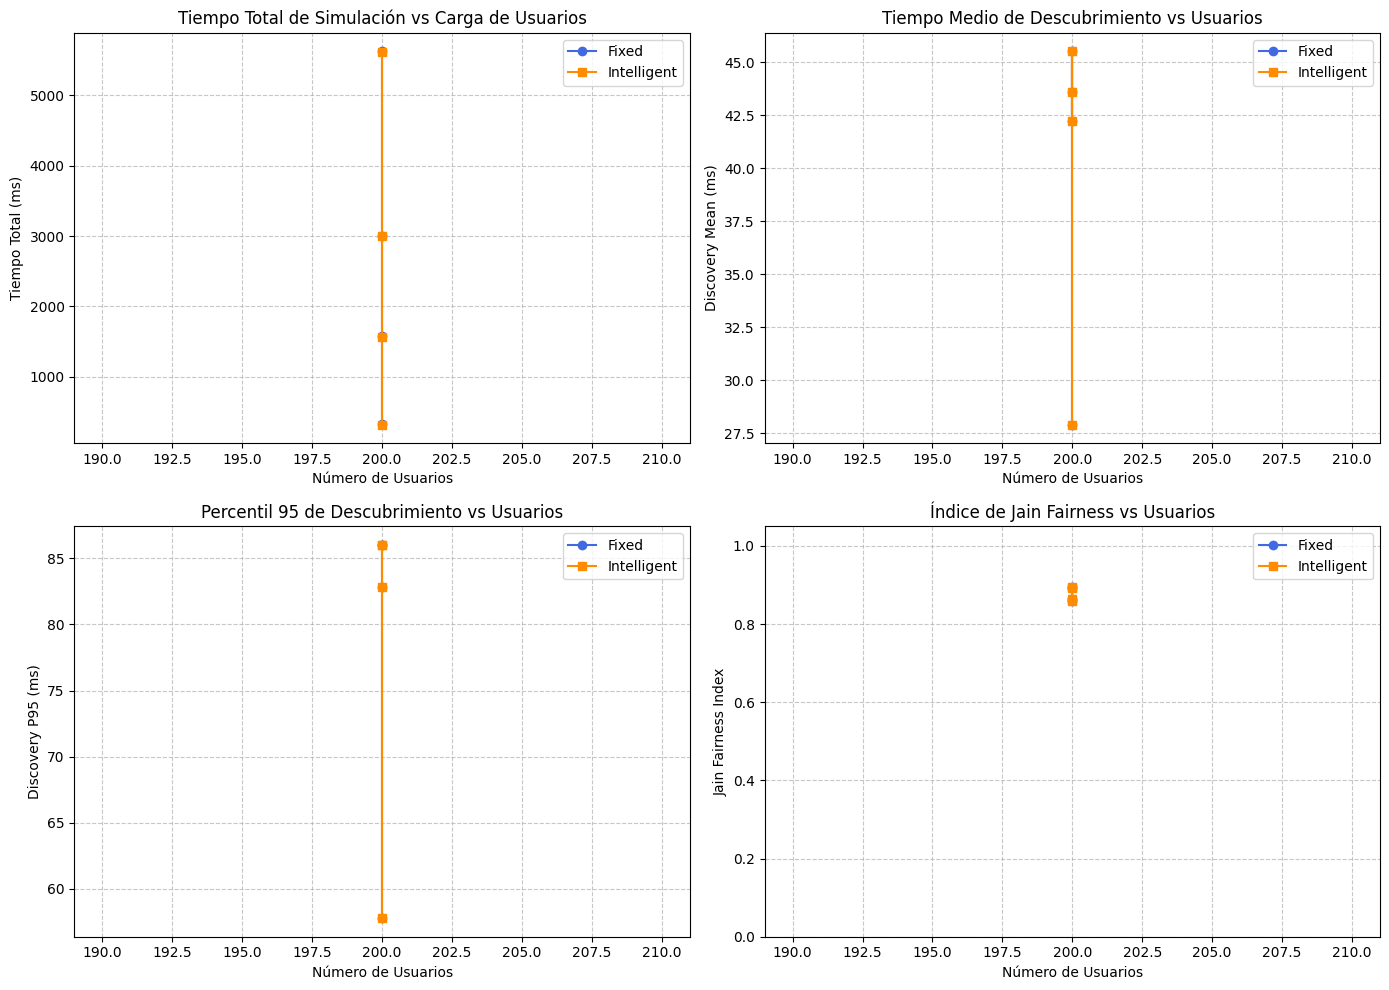

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. MODELO DE ARRAY Y FÍSICA (array_model.py)
# ==========================================
def calculate_wavelength(frequency_hz):
    c = 3e8
    return c / frequency_hz

def array_factor(theta_deg, N, wavelength, d, beta_deg):
    k = 2 * np.pi / wavelength
    theta_rad = np.radians(theta_deg)
    beta = np.radians(beta_deg)

    term = k * d * np.sin(theta_rad) + beta
    AF = np.zeros_like(theta_rad, dtype=complex)
    for n in range(N):
        AF += np.exp(1j * n * term)

    AF_mag = np.abs(AF) / N
    AF_db = 20 * np.log10(np.maximum(AF_mag, 1e-5))
    return AF_db

# ==========================================
# 2. GENERACIÓN DE USUARIOS RIGUROSA (users.py)
# ==========================================
def generate_manual_test_users():
    """Genera los 5 usuarios estrictos para la prueba de fuego obligatoria."""
    return [
        {
            'id': 0, 'x': -38.3, 'y': 32.1, 'height': 1.5, 'distance': 50.0,
            'angle': -50.0, 'traffic_demand': 500, 'priority': 50,
            'discovered': False, 'creation_time': 0.0, 'discovery_time': None,
            'first_service_time': None, 'completion_time': None,
            'remaining_data': 500, 'service_received': 0
        },
        {
            'id': 1, 'x': -8.7, 'y': 49.2, 'height': 1.5, 'distance': 50.0,
            'angle': -10.0, 'traffic_demand': 1000, 'priority': 80,
            'discovered': False, 'creation_time': 0.0, 'discovery_time': None,
            'first_service_time': None, 'completion_time': None,
            'remaining_data': 1000, 'service_received': 0
        },
        {
            'id': 2, 'x': 8.7, 'y': 49.2, 'height': 1.5, 'distance': 50.0,
            'angle': 10.0, 'traffic_demand': 200, 'priority': 20,
            'discovered': False, 'creation_time': 0.0, 'discovery_time': None,
            'first_service_time': None, 'completion_time': None,
            'remaining_data': 200, 'service_received': 0
        },
        {
            'id': 3, 'x': 25.0, 'y': 43.3, 'height': 1.5, 'distance': 50.0,
            'angle': 30.0, 'traffic_demand': 1500, 'priority': 90,
            'discovered': False, 'creation_time': 0.0, 'discovery_time': None,
            'first_service_time': None, 'completion_time': None,
            'remaining_data': 1500, 'service_received': 0
        },
        {
            'id': 4, 'x': 38.3, 'y': 32.1, 'height': 1.5, 'distance': 50.0,
            'angle': 50.0, 'traffic_demand': 400, 'priority': 40,
            'discovered': False, 'creation_time': 0.0, 'discovery_time': None,
            'first_service_time': None, 'completion_time': None,
            'remaining_data': 400, 'service_received': 0
        }
    ]

def generate_users(n_users, area_min_dist=10.0, area_max_dist=100.0, seed=42):
    """Genera población de usuarios con idéntica semilla y distribución dentro del sector de haz (-60° a +60°)."""
    np.random.seed(seed)
    users = []
    for i in range(n_users):
        r = np.random.uniform(area_min_dist, area_max_dist)
        angle_deg = np.random.uniform(-60.0, 60.0)
        angle_rad = np.radians(angle_deg)

        x = r * np.sin(angle_rad)
        y = r * np.cos(angle_rad)

        demand = int(np.random.randint(200, 1500))

        users.append({
            'id': i,
            'x': float(x),
            'y': float(y),
            'height': 1.5,
            'distance': float(r),
            'angle': float(angle_deg),
            'traffic_demand': demand,
            'priority': int(np.random.randint(10, 100)),
            'discovered': False,
            'creation_time': 0.0,
            'discovery_time': None,
            'first_service_time': None,
            'completion_time': None,
            'remaining_data': demand,
            'service_received': 0
        })
    return users

# ==========================================
# 3. MOTOR DE SIMULACIÓN Y SCHEDULING (scanner.py)
# ==========================================
def run_simulation(users, beam_angles, algorithm='fixed', beamwidth=10.0,
                   scan_time_ms=2.0, trans_time_ms=5.0, max_timeout_ms=100000.0, debug=False):
    """
    Ejecuta la simulación temporal paso a paso separando exploración, descubrimiento,
    servicio parcial y completitud.
    """
    sim_users = [u.copy() for u in users]
    current_time_ms = 0.0

    sector_memory = {
        angle: {
            'detected_users': [],
            'pending_traffic': 0.0,
            'priority_sum': 0.0,
            'waiting_time': 0.0,
            'last_scan_time': -1.0
        } for angle in beam_angles
    }

    fixed_order = list(beam_angles)
    active_route = list(fixed_order)
    sweeps_completed = 0
    timeout_reached = False

    if debug:
        print(f"\n--- INICIANDO SIMULACIÓN [{algorithm.upper()}] (Total Usuarios: {len(sim_users)}) ---")

    while not all(u['completion_time'] is not None for u in sim_users):
        if current_time_ms >= max_timeout_ms:
            timeout_reached = True
            if debug:
                print(f"[!] TIMEOUT ALCANZADO EN t={current_time_ms} ms")
            break

        if algorithm == 'intelligent':
            if sweeps_completed < 1:
                active_route = list(fixed_order)
            else:
                scored_angles = []
                for angle in beam_angles:
                    mem = sector_memory[angle]
                    time_since_last = current_time_ms - mem['last_scan_time']

                    w1, w2, w3, w4 = 1.0, 1.5, 0.5, 1.0
                    score = (w1 * len(mem['detected_users'])) + \
                            (w2 * (mem['pending_traffic'] / 1000.0)) + \
                            (w3 * (time_since_last / 10.0)) + \
                            (w4 * (mem['priority_sum'] / 100.0))

                    scored_angles.append((score, angle))

                scored_angles.sort(key=lambda x: x[0], reverse=True)
                active_route = [angle for _, angle in scored_angles]
        else:
            active_route = list(fixed_order)

        for beam_angle in active_route:
            current_time_ms += scan_time_ms
            sector_memory[beam_angle]['last_scan_time'] = current_time_ms

            detected_in_this_step = []
            active_sector_users = []

            for u in sim_users:
                if abs(u['angle'] - beam_angle) <= (beamwidth / 2.0):
                    active_sector_users.append(u)
                    detected_in_this_step.append(f"U{u['id']}")

                    if not u['discovered']:
                        u['discovered'] = True
                        u['discovery_time'] = current_time_ms
                        if debug and len(sim_users) <= 10:
                            print(f"t={current_time_ms:5.1f} ms | U{u['id']} DESCUBIERTO (Ángulo: {u['angle']}°) térmico")

            pending_traffic_sec = sum(u['remaining_data'] for u in active_sector_users if u['completion_time'] is None)
            priority_sum_sec = sum(u['priority'] for u in active_sector_users if u['completion_time'] is None)

            sector_memory[beam_angle]['detected_users'] = [u['id'] for u in active_sector_users if u['completion_time'] is None]
            sector_memory[beam_angle]['pending_traffic'] = pending_traffic_sec
            sector_memory[beam_angle]['priority_sum'] = priority_sum_sec

            unserved_in_sector = [u for u in active_sector_users if u['completion_time'] is None]
            if unserved_in_sector:
                unserved_in_sector.sort(key=lambda x: (x['priority'], x['remaining_data']), reverse=True)
                target_user = unserved_in_sector[0]

                current_time_ms += trans_time_ms

                if target_user['first_service_time'] is None:
                    target_user['first_service_time'] = current_time_ms

                served_chunk = min(300, target_user['remaining_data'])
                target_user['remaining_data'] -= served_chunk
                target_user['service_received'] += served_chunk

                if target_user['remaining_data'] <= 0:
                    target_user['completion_time'] = current_time_ms
                    if debug and len(sim_users) <= 10:
                        print(f"t={current_time_ms:5.1f} ms | U{target_user['id']} COMPLETAMENTE SERVIDO")

            if debug and len(sim_users) <= 10 and detected_in_this_step:
                print(f"t={current_time_ms:5.1f} ms | Beam={beam_angle:3d}° | Detectados: {detected_in_this_step}")

            if all(u['completion_time'] is not None for u in sim_users):
                break

        sweeps_completed += 1

    return sim_users, current_time_ms, timeout_reached

# ==========================================
# 4. CÁLCULO DE MÉTRICAS Y JAIN FAIRNESS (metrics.py)
# ==========================================
def calculate_jains_fairness(users):
    services = np.array([u['service_received'] for u in users], dtype=float)
    n = len(services)
    if n == 0 or np.sum(services) == 0:
        return "N/A"
    sum_val = np.sum(services)
    sum_sq = np.sum(services**2)
    if sum_sq == 0:
        return "N/A"
    return float((sum_val**2) / (n * sum_sq))

def evaluate_performance(sim_users, total_time, timeout_reached):
    disc_times = [u['discovery_time'] - u['creation_time'] for u in sim_users if u['discovery_time'] is not None]
    first_serv_times = [u['first_service_time'] - u['creation_time'] for u in sim_users if u['first_service_time'] is not None]
    comp_times = [u['completion_time'] - u['creation_time'] for u in sim_users if u['completion_time'] is not None]

    total_bits_served = sum(u['service_received'] for u in sim_users)
    throughput = total_bits_served / (total_time / 1000.0) if total_time > 0 else 0.0

    metrics = {
        'total_time_ms': total_time,
        'timeout': timeout_reached,
        'users_completed': f"{len(comp_times)}/{len(sim_users)}",
        'discovery_mean': np.mean(disc_times) if disc_times else float('nan'),
        'discovery_median': np.median(disc_times) if disc_times else float('nan'),
        'discovery_p95': np.percentile(disc_times, 95) if len(disc_times) > 1 else (disc_times[0] if disc_times else float('nan')),
        'first_service_mean': np.mean(first_serv_times) if first_serv_times else float('nan'),
        'completion_mean': np.mean(comp_times) if comp_times else float('nan'),
        'throughput': throughput,
        'fairness_index': calculate_jains_fairness(sim_users)
    }
    return metrics

# ==========================================
# 5. VISUALIZACIÓN ANALÍTICA (visualization.py)
# ==========================================
def plot_comparative_metrics(df_results):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    axes[0, 0].plot(df_results['Usuarios'], df_results['Fixed Total (ms)'], marker='o', label='Fixed', color='royalblue')
    axes[0, 0].plot(df_results['Usuarios'], df_results['Intelligent Total (ms)'], marker='s', label='Intelligent', color='darkorange')
    axes[0, 0].set_title('Tiempo Total de Simulación vs Carga de Usuarios')
    axes[0, 0].set_xlabel('Número de Usuarios')
    axes[0, 0].set_ylabel('Tiempo Total (ms)')
    axes[0, 0].legend()
    axes[0, 0].grid(True, linestyle='--', alpha=0.7)

    axes[0, 1].plot(df_results['Usuarios'], df_results['Fixed Disc Mean'], marker='o', label='Fixed', color='royalblue')
    axes[0, 1].plot(df_results['Usuarios'], df_results['Intelligent Disc Mean'], marker='s', label='Intelligent', color='darkorange')
    axes[0, 1].set_title('Tiempo Medio de Descubrimiento vs Usuarios')
    axes[0, 1].set_xlabel('Número de Usuarios')
    axes[0, 1].set_ylabel('Discovery Mean (ms)')
    axes[0, 1].legend()
    axes[0, 1].grid(True, linestyle='--', alpha=0.7)

    axes[1, 0].plot(df_results['Usuarios'], df_results['Fixed P95'], marker='o', label='Fixed', color='royalblue')
    axes[1, 0].plot(df_results['Usuarios'], df_results['Intelligent P95'], marker='s', label='Intelligent', color='darkorange')
    axes[1, 0].set_title('Percentil 95 de Descubrimiento vs Usuarios')
    axes[1, 0].set_xlabel('Número de Usuarios')
    axes[1, 0].set_ylabel('Discovery P95 (ms)')
    axes[1, 0].legend()
    axes[1, 0].grid(True, linestyle='--', alpha=0.7)

    fair_fixed = pd.to_numeric(df_results['Fixed Fairness'].replace('N/A', np.nan))
    fair_intel = pd.to_numeric(df_results['Intelligent Fairness'].replace('N/A', np.nan))
    axes[1, 1].plot(df_results['Usuarios'], fair_fixed, marker='o', label='Fixed', color='royalblue')
    axes[1, 1].plot(df_results['Usuarios'], fair_intel, marker='s', label='Intelligent', color='darkorange')
    axes[1, 1].set_title('Índice de Jain Fairness vs Usuarios')
    axes[1, 1].set_xlabel('Número de Usuarios')
    axes[1, 1].set_ylabel('Jain Fairness Index')
    axes[1, 1].set_ylim(0, 1.05)
    axes[1, 1].legend()
    axes[1, 1].grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

# ==========================================
# 6. EJECUCIÓN PRINCIPAL Y VALIDACIÓN PASO A PASO
# ==========================================
if __name__ == "__main__":
    beam_angles = [-60, -50, -40, -30, -20, -10, 0, 10, 20, 30, 40, 50, 60]

    print("==================================================")
    print("PASO 1: PRUEBA DE FUEGO OBLIGATORIA (5 USUARIOS)")
    print("==================================================")

    test_users_fixed = generate_manual_test_users()
    test_users_intel = [u.copy() for u in test_users_fixed]

    res_f, time_f, timeout_f = run_simulation(test_users_fixed, beam_angles, algorithm='fixed', debug=True)
    res_i, time_i, timeout_i = run_simulation(test_users_intel, beam_angles, algorithm='intelligent', debug=True)

    print(f"\n[✔] Resultado 5 Usuarios -> Fijo: {time_f} ms | Inteligente: {time_i} ms\n")

    print("==================================================")
    print("PASO 2: VALIDACIÓN INTERMEDIA (10 USUARIOS TRACE)")
    print("==================================================")
    users_10_base = generate_users(n_users=10, seed=42)
    u10_f = [u.copy() for u in users_10_base]
    u10_i = [u.copy() for u in users_10_base]

    res10_f, t10_f, _ = run_simulation(u10_f, beam_angles, algorithm='fixed', debug=False)
    res10_i, t10_i, _ = run_simulation(u10_i, beam_angles, algorithm='intelligent', debug=False)
    m10_f = evaluate_performance(res10_f, t10_f, False)
    m10_i = evaluate_performance(res10_i, t10_i, False)
    print(f"10 Usuarios -> Fijo Total: {t10_f} ms (Disc Mean: {m10_f['discovery_mean']:.1f} ms) | Inteligente Total: {t10_i} ms (Disc Mean: {m10_i['discovery_mean']:.1f} ms)")

    print("\n==================================================")
    print("PASO 3: EXPERIMENTOS MASIVOS (10, 50, 100, 200 USUARIOS)")
    print("==================================================")

    user_counts = [10, 50, 100, 200]
    experiment_results = []

    for n in user_counts:
        base_population = generate_users(n_users=n, seed=42)

        pop_fixed = [u.copy() for u in base_population]
        pop_intel = [u.copy() for u in base_population]

        tf_users, time_f_val, timeout_f_flag = run_simulation(pop_fixed, beam_angles, algorithm='fixed', max_timeout_ms=150000.0, debug=False)
        ti_users, time_i_val, timeout_i_flag = run_simulation(pop_intel, beam_angles, algorithm='intelligent', max_timeout_ms=150000.0, debug=False)

        # Corrección aplicada: Se evalúan los resultados devueltos por el motor (`tf_users` y `ti_users`)
        metrics_f = evaluate_performance(tf_users, time_f_val, timeout_f_flag)
        metrics_i = evaluate_performance(ti_users, time_i_val, timeout_i_flag)

        experiment_results.append({
            'Usuarios': n,
            'Fixed Total (ms)': f"{time_f_val}{' (TIMEOUT)' if timeout_f_flag else ''}",
            'Intelligent Total (ms)': f"{time_i_val}{' (TIMEOUT)' if timeout_i_flag else ''}",
            'Fixed Disc Mean': f"{metrics_f['discovery_mean']:.1f}" if not np.isnan(metrics_f['discovery_mean']) else "NaN",
            'Intelligent Disc Mean': f"{metrics_i['discovery_mean']:.1f}" if not np.isnan(metrics_i['discovery_mean']) else "NaN",
            'Fixed P95': f"{metrics_f['discovery_p95']:.1f}" if not np.isnan(metrics_f['discovery_p95']) else "NaN",
            'Intelligent P95': f"{metrics_i['discovery_p95']:.1f}" if not np.isnan(metrics_i['discovery_p95']) else "NaN",
            'Fixed Fairness': metrics_f['fairness_index'] if metrics_f['fairness_index'] == "N/A" else f"{metrics_f['fairness_index']:.3f}",
            'Intelligent Fairness': metrics_i['fairness_index'] if metrics_i['fairness_index'] == "N/A" else f"{metrics_i['fairness_index']:.3f}"
        })

    df_final = pd.DataFrame(experiment_results)
    print("\n")
    print(df_final.to_string(index=False))

    print("\n[+] Generando gráficos comparativos avanzados para tesis...")
    df_plot = pd.DataFrame([{
        'Usuarios': n,
        'Fixed Total (ms)': float(str(r['Fixed Total (ms)']).replace(' (TIMEOUT)', '')),
        'Intelligent Total (ms)': float(str(r['Intelligent Total (ms)']).replace(' (TIMEOUT)', '')),
        'Fixed Disc Mean': float(r['Fixed Disc Mean']) if r['Fixed Disc Mean'] != 'NaN' else 0,
        'Intelligent Disc Mean': float(r['Intelligent Disc Mean']) if r['Intelligent Disc Mean'] != 'NaN' else 0,
        'Fixed P95': float(r['Fixed P95']) if r['Fixed P95'] != 'NaN' else 0,
        'Intelligent P95': float(r['Intelligent P95']) if r['Intelligent P95'] != 'NaN' else 0,
        'Fixed Fairness': r['Fixed Fairness'],
        'Intelligent Fairness': r['Intelligent Fairness']
    } for r in experiment_results])

    plot_comparative_metrics(df_plot)